# US Accidents · Predicting reported traffic impact

Train a four-class classifier for an **already-recorded accident**. The label `Severity` runs from 1 to 4 and describes impact on traffic. Level 4 is the highest reported impact. The model can help prioritize road-safety investigations. The dataset does not measure injuries or traffic exposure, so these results cannot estimate the chance of a crash per trip or establish what caused one.

**Run on Kaggle**

1. Import this notebook and add [US Accidents (2016–2023)](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents) as an input.
2. Use a CPU session and choose **Run All**. The notebook finds `US_Accidents_March23.csv` under `/kaggle/input`.
3. Review the test results and interactive dashboard. The trained classifier, test metrics and dashboard HTML are saved to `/kaggle/working`.

See [the dataset paper](https://arxiv.org/abs/1906.05409) for how the records were collected.

The included outputs come from a local run on the March 2023 CSV using the settings below. Running all cells recreates the results and exports the files in your current session.

## 1. Settings

The CSV has about 7.7 million records. Read only the needed columns in blocks of 100,000 rows and sample randomly from every block. This keeps memory bounded and gives each period and state a chance to appear. The sample is **not** balanced by severity, so evaluation preserves the class mix of the sampled records.

`SAMPLE_FRACTION = 0.20` keeps about one fifth of the file before the date filters. `MAX_TRAIN_ROWS` caps what the algorithms fit on. For a quick run, try `SAMPLE_FRACTION = 0.05` and `MAX_TRAIN_ROWS = 150_000`. The CSV still needs to be scanned.

In [4]:
import json
import os
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, f1_score, precision_recall_curve, recall_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
THREADS = min(4, os.cpu_count() or 1)
SAMPLE_FRACTION = 0.20
MAX_TRAIN_ROWS = 650_000
CHUNK_ROWS = 100_000
CLASS_NAMES = ["Level 1", "Level 2", "Level 3", "Level 4"]
CLASS_IDS = np.arange(len(CLASS_NAMES))

TRAIN_START = "2020-01-01"
VALID_START = "2022-06-01"
TEST_START = "2022-07-01"
SHIFT_START = "2022-10-01"
HELD_OUT_STATES = ["CO", "OR", "VA"]

# Leave CSV_PATH as None on Kaggle. Locally, set it if the CSV is elsewhere.
CSV_PATH = None
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path("severity_outputs")

## 2. Load records and keep the tests separate

| Set | Dates | States |
|---|---|---|
| Training | Jan 2020 to May 2022 | All except CO, OR and VA |
| Validation | Jun 2022 | All except CO, OR and VA |
| Time test | Jul to Sep 2022 | All except CO, OR and VA |
| Location test | Jul to Sep 2022 | CO, OR and VA only |
| Later reporting shift | Oct 2022 to Mar 2023 | All except CO, OR and VA |

June provides a full validation month just before the tests. Training through May includes recent examples of all four levels. The primary time and location tests cover the same quarter with all four labels represented. The location test adds the difficulty of unseen states. From Oct 2022 onward the CSV switches to a single reporting provider and only two labels appear. We report that later period separately so its class mix does not dominate the four-class results.

In [5]:
NUMERIC_WEATHER = [
    "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
    "Wind_Speed(mph)", "Precipitation(in)",
]
ROAD_FLAGS = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal",
]
LOCATION = ["Start_Lat", "Start_Lng"]
RECORDED_CATEGORIES = ["State", "Weather_Condition", "Sunrise_Sunset", "Civil_Twilight"]
RAW_FEATURES = ["Start_Time", "Street"] + LOCATION + NUMERIC_WEATHER + ROAD_FLAGS + RECORDED_CATEGORIES
READ_COLUMNS = ["Severity", "Source"] + RAW_FEATURES

if CSV_PATH is None:
    kaggle_files = sorted(Path("/kaggle/input").rglob("US_Accidents_March23.csv"))
    CSV_PATH = kaggle_files[0] if kaggle_files else Path("US_Accidents_March23.csv")
CSV_PATH = Path(CSV_PATH)
if not CSV_PATH.is_file():
    raise FileNotFoundError("Add the US Accidents dataset as a Kaggle input or set CSV_PATH above.")
if not 0 < SAMPLE_FRACTION <= 1:
    raise ValueError("SAMPLE_FRACTION must be above 0 and at most 1.")

saved_chunks = {
    "Train": [], "Validation": [], "Time test": [],
    "Location test": [], "Later reporting shift": [],
}
scanned_rows = 0
print("Reading", CSV_PATH.name)
for number, block in enumerate(pd.read_csv(
    CSV_PATH, usecols=READ_COLUMNS, chunksize=CHUNK_ROWS,
    dtype={column: "float32" for column in LOCATION + NUMERIC_WEATHER},
)):
    scanned_rows += len(block)
    sample = block.sample(frac=SAMPLE_FRACTION, random_state=SEED + number).copy()
    sample["Start_Time"] = pd.to_datetime(sample["Start_Time"], format="mixed", errors="coerce")
    sample = sample.dropna(subset=["Start_Time", "State"])
    sample = sample.loc[sample["Severity"].isin([1, 2, 3, 4])]
    known_state = ~sample["State"].isin(HELD_OUT_STATES)
    date = sample["Start_Time"]
    split_masks = {
        "Train": known_state & date.ge(TRAIN_START) & date.lt(VALID_START),
        "Validation": known_state & date.ge(VALID_START) & date.lt(TEST_START),
        "Time test": known_state & date.ge(TEST_START) & date.lt(SHIFT_START),
        "Location test": ~known_state & date.ge(TEST_START) & date.lt(SHIFT_START),
        "Later reporting shift": known_state & date.ge(SHIFT_START),
    }
    for name, mask in split_masks.items():
        if mask.any():
            saved_chunks[name].append(sample.loc[mask])
    if (number + 1) % 25 == 0:
        print(f"Scanned {scanned_rows:,} rows...")

if any(len(parts) == 0 for parts in saved_chunks.values()):
    raise ValueError("A split is empty. Check the CSV, sample fraction and split dates.")
splits = {name: pd.concat(parts, ignore_index=True) for name, parts in saved_chunks.items()}
del saved_chunks, block, sample
if len(splits["Train"]) > MAX_TRAIN_ROWS:
    splits["Train"] = splits["Train"].sample(n=MAX_TRAIN_ROWS, random_state=SEED).reset_index(drop=True)

train_data = splits["Train"]
validation_data = splits["Validation"]
test_data = splits["Time test"]
location_data = splits["Location test"]

assert train_data["Start_Time"].max() < validation_data["Start_Time"].min()
assert validation_data["Start_Time"].max() < test_data["Start_Time"].min()
assert set(location_data["State"]) == set(HELD_OUT_STATES), "Increase the sample to include all held-out states."
assert set(train_data["State"]).isdisjoint(location_data["State"])
assert set(validation_data["State"]).isdisjoint(location_data["State"])

print(f"Scanned {scanned_rows:,} CSV rows.")
for name in ["Train", "Validation"]:
    part = splits[name]
    print(f"{name:12} {len(part):>9,} rows  |  {part['Start_Time'].min():%Y-%m-%d} to {part['Start_Time'].max():%Y-%m-%d}")

Reading US_Accidents_March23.csv
Scanned 2,500,000 rows...
Scanned 5,000,000 rows...
Scanned 7,500,000 rows...
Scanned 7,728,394 CSV rows.
Train          650,000 rows  |  2020-01-01 to 2022-05-31
Validation      23,316 rows  |  2022-06-01 to 2022-06-30


## 3. Inspect imbalance and prepare inputs

The classifier uses recorded weather, time, lighting, starting coordinates and road context. `Road_Type` is a rough label from the street text (for example, Interstate or Road). The road flags describe nearby features such as a junction or traffic signal. Missing values stay visible to the model, through either explicit categories or each algorithm's numeric handling.

Time inputs include the hour, weekday, month and year. The year helps the model learn changes in the recorded patterns across years.

Excluded from training are report IDs, provider names, exact street names, descriptions, affected distance, end location and end time. Some of those fields encode reporting practices or describe the impact after it is known. Recorded weather can come from the nearest observation in time. A live use case would need weather that was available when making the prediction.

The label is converted from **1–4** to **0–3** for training. Results and example predictions use the original levels. The two least frequent training classes define the minority-recall metric.

,Training rows,Training %,Validation rows,Validation %
Level 1,6850,1.05,1449,6.21
Level 2,560524,86.23,19810,84.96
Level 3,70079,10.78,1556,6.67
Level 4,12547,1.93,501,2.15


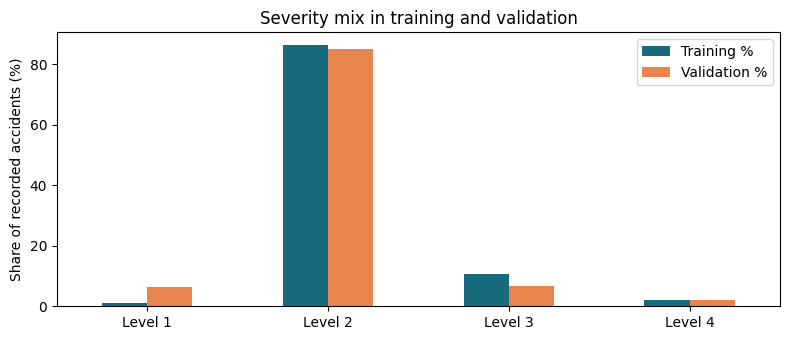

Minority classes from training: ['Level 1', 'Level 4']


In [6]:
def severity_counts(frame):
    return frame["Severity"].value_counts().reindex([1, 2, 3, 4], fill_value=0)


train_counts = severity_counts(train_data)
valid_counts = severity_counts(validation_data)
if (train_counts == 0).any() or (valid_counts == 0).any():
    raise ValueError("Training and validation need all four levels. Increase SAMPLE_FRACTION.")

majority_class = train_counts.idxmax() - 1
minority_classes = train_counts.nsmallest(2).index.to_numpy() - 1
class_shares = pd.DataFrame({
    "Training rows": train_counts,
    "Training %": 100 * train_counts / len(train_data),
    "Validation rows": valid_counts,
    "Validation %": 100 * valid_counts / len(validation_data),
})
class_shares.index = CLASS_NAMES
display(class_shares.round(2))
class_shares[["Training %", "Validation %"]].plot.bar(
    figsize=(8, 3.5), rot=0, ylabel="Share of recorded accidents (%)",
    title="Severity mix in training and validation", color=["#176b7c", "#e8844e"],
)
plt.tight_layout()
plt.show()
print("Minority classes from training:", [CLASS_NAMES[level] for level in minority_classes])

In [7]:
NUMERIC_FEATURES = LOCATION + NUMERIC_WEATHER + ROAD_FLAGS + ["Hour", "Day_Of_Week", "Month", "Year"]
CATEGORY_FEATURES = RECORDED_CATEGORIES + ["Road_Type"]
FEATURES = NUMERIC_FEATURES + CATEGORY_FEATURES


def road_type(street):
    """Group common street labels without giving the model the full street name."""
    street = street.astype("string").str.upper().str.strip().fillna("")
    return np.select(
        [
            street.str.match(r"^(?:I[- ]?\d|INTERSTATE\b)").to_numpy(dtype=bool),
            street.str.match(r"^(?:US[- ]?\d|U\.S\.\s*\d|[A-Z]{2}-\d)").to_numpy(dtype=bool),
            street.str.contains(r"\b(?:HWY|HIGHWAY|RTE|ROUTE|FWY|FREEWAY)\b").to_numpy(dtype=bool),
            street.str.contains(r"\b(?:RAMP|EXIT)\b").to_numpy(dtype=bool),
            street.str.contains(r"\b(?:RD|ROAD|DR|DRIVE|LN|LANE)\b").to_numpy(dtype=bool),
            street.str.contains(r"\b(?:ST|STREET|AVE|AVENUE|BLVD|BOULEVARD)\b").to_numpy(dtype=bool),
            street.eq("").to_numpy(dtype=bool),
        ],
        ["Interstate", "Numbered route", "Highway/route", "Ramp",
         "Road/drive/lane", "Street/avenue", "Unknown"],
        default="Other",
    )


def make_features(records):
    """Prepare the same inputs for training, evaluation and later predictions."""
    data = pd.DataFrame(index=records.index)
    timestamp = pd.to_datetime(records["Start_Time"], format="mixed", errors="coerce")
    data["Hour"] = timestamp.dt.hour.astype("float32")
    data["Day_Of_Week"] = timestamp.dt.dayofweek.astype("float32")
    data["Month"] = timestamp.dt.month.astype("float32")
    data["Year"] = timestamp.dt.year.astype("float32")
    data["Road_Type"] = road_type(records["Street"])

    for column in LOCATION + NUMERIC_WEATHER:
        data[column] = pd.to_numeric(records[column], errors="coerce").astype("float32")
    for column in ROAD_FLAGS:
        values = records[column].astype("string").str.lower().str.strip()
        data[column] = values.map({"true": 1, "false": 0, "1": 1, "0": 0}).astype("float32")
    for column in RECORDED_CATEGORIES:
        values = records[column].astype("string").str.strip().replace("", pd.NA)
        data[column] = values.fillna("Unknown").astype(object)
    return data[FEATURES]


def make_labels(records):
    return records["Severity"].to_numpy(dtype=int) - 1


X_train = make_features(train_data)
y_train = make_labels(train_data)
X_valid = make_features(validation_data)
y_valid = make_labels(validation_data)
display(X_train.head(3))

,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Amenity,Bump,...,Traffic_Signal,Hour,Day_Of_Week,Month,Year,State,Weather_Condition,Sunrise_Sunset,Civil_Twilight,Road_Type
0,35.290611,-118.748199,39.0,100.0,25.870001,6.0,3.0,0.0,0.0,0.0,...,0.0,2.0,2.0,4.0,2020.0,CA,Light Rain,Night,Night,Numbered route
1,39.049568,-94.364754,89.0,43.0,28.969999,10.0,7.0,0.0,0.0,0.0,...,0.0,17.0,4.0,9.0,2021.0,MO,Fair,Day,Day,Numbered route
2,32.850861,-96.771614,40.0,63.0,29.809999,10.0,3.0,0.0,0.0,0.0,...,1.0,1.0,6.0,1.0,2021.0,TX,Cloudy,Night,Night,Numbered route


## 4. Compare three algorithms

- **Logistic regression** is a classification baseline that learns a linear relationship between inputs and class scores.
- **Extra Trees** averages many randomized trees. It can learn interactions such as poor visibility at a junction after dark.
- **Histogram gradient boosting** builds trees in sequence to improve on earlier errors. It groups numeric values into bins to train efficiently.

The models see the same training rows. For the first two models, one-hot encoding gives each common category a 0/1 column. Boosting handles categories within its trees. Each model learns its preprocessing from training data. We also test a boosting configuration that gives rarer training labels more weight. A **majority-class baseline** always predicts the most common training class.

In [8]:
# A shared setup for logistic regression and Extra Trees.
def one_hot_inputs(scale=False):
    numbers = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    if scale:
        numbers = make_pipeline(numbers, StandardScaler())
    return ColumnTransformer([
        ("numbers", numbers, NUMERIC_FEATURES),
        ("categories", OneHotEncoder(handle_unknown="ignore", min_frequency=0.001,
                                     dtype=np.float32), CATEGORY_FEATURES),
    ])


boost_inputs = ColumnTransformer([
    ("numbers", "passthrough", NUMERIC_FEATURES),
    ("categories", OrdinalEncoder(
        handle_unknown="use_encoded_value", unknown_value=np.nan,
        max_categories=64, dtype=np.float32,
    ), CATEGORY_FEATURES),
])
category_positions = list(range(len(NUMERIC_FEATURES), len(FEATURES)))

models = {
    "Logistic regression": make_pipeline(
        one_hot_inputs(scale=True), LogisticRegression(max_iter=300, C=0.5),
    ),
    "Extra Trees": make_pipeline(
        one_hot_inputs(), ExtraTreesClassifier(
            n_estimators=100, max_depth=20, min_samples_leaf=12,
            max_features=0.65, n_jobs=THREADS, random_state=SEED,
        ),
    ),
    "Histogram gradient boosting": make_pipeline(
        boost_inputs, HistGradientBoostingClassifier(
            max_iter=220, learning_rate=0.10, max_leaf_nodes=63,
            min_samples_leaf=40, l2_regularization=1.0,
            categorical_features=category_positions,
            early_stopping=False, random_state=SEED,
        ),
    ),
}
weighted_boost_name = "Histogram boosting (weighted)"
models[weighted_boost_name] = clone(models["Histogram gradient boosting"])

# Partial inverse-frequency weighting is gentler than making every class equal.
class_weights = (train_counts.to_numpy() / len(y_train)) ** -0.4
row_weights = class_weights[y_train]
row_weights = row_weights / row_weights.mean()
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

## 5. Improve the decision rule using validation

Each trained model produces a score for each level. The default prediction is the level with the highest score. Since the common class can win too easily, we also try multiplying each less frequent class's score by a few different amounts. This lets us favor classes the model misses or reduce false alarms. We keep the settings that improve validation **macro-F1**, the average F1 score across the four levels.

**Minority recall** averages the recall of the two least common training labels. Level 4 precision asks how many Level 4 predictions were correct. Level 4 recall asks how many actual Level 4 reports were detected. Average precision also measures Level 4 ranking across possible cutoffs. Review all of these alongside accuracy.

In [9]:
def predict_levels(scores, multipliers):
    """Choose the largest adjusted class score for each accident."""
    return (scores * multipliers).argmax(axis=1)


def tune_multipliers(scores, actual):
    """Try a few settings for one class at a time, using validation only."""
    multipliers = np.ones(len(CLASS_NAMES))
    candidate_factors = [0.125, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0, 8.0]
    best_f1 = f1_score(actual, predict_levels(scores, multipliers), average="macro")

    # Revisit each class once because changing one score affects the others.
    for attempt in range(2):
        for level in CLASS_IDS:
            if level == majority_class:
                continue
            best_factor = multipliers[level]
            for factor in candidate_factors:
                trial = multipliers.copy()
                trial[level] = factor
                predictions = predict_levels(scores, trial)
                score = f1_score(actual, predictions, average="macro")
                if score > best_f1 + 1e-6:
                    best_f1 = score
                    best_factor = factor
            multipliers[level] = best_factor
    return multipliers


def metric_row(actual, predictions, level_4_scores):
    class_report = classification_report(
        actual, predictions, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    return {
        "Accuracy": accuracy_score(actual, predictions),
        "Macro-F1": class_report["macro avg"]["f1-score"],
        "Macro precision": class_report["macro avg"]["precision"],
        "Balanced accuracy": class_report["macro avg"]["recall"],
        "Minority recall": recall_score(
            actual, predictions, labels=minority_classes, average="macro", zero_division=0,
        ),
        "Level 4 precision": class_report["Level 4"]["precision"],
        "Level 4 recall": class_report["Level 4"]["recall"],
        "Level 4 average precision": average_precision_score(actual == 3, level_4_scores),
        "Levels 3–4 recall": recall_score(actual >= 2, predictions >= 2, zero_division=0),
    }

Training Logistic regression
Finished in 71.2 seconds.
Training Extra Trees
Finished in 457.4 seconds.
Training Histogram gradient boosting
Finished in 86.0 seconds.
Training Histogram boosting (weighted)
Finished in 84.5 seconds.


Accuracy  Macro-F1  Macro precision  \
Model                         Decision                                        
Majority baseline             Default     0.8496    0.2297           0.2124   
Logistic regression           Default     0.8481    0.2411           0.2939   
                              Tuned       0.7910    0.2962           0.3680   
Extra Trees                   Default     0.8524    0.2813           0.5310   
                              Tuned       0.8168    0.4606           0.4701   
Histogram gradient boosting   Default     0.8561    0.3237           0.5853   
                              Tuned       0.8159    0.4927           0.4839   
Histogram boosting (weighted) Default     0.8507    0.4305           0.5316   
                              Tuned       0.8043    0.4950           0.4730   

                                        Balanced accuracy  Minority recall  \
Model                         Decision                                       
Majority baseline             Default              0.2500           0.0000   
Logistic regression           Default              0.2553           0.0000   
                              Tuned                0.3156           0.0124   
Extra Trees                   Default              0.2782           0.0083   
                              Tuned                0.4585           0.3023   
Histogram gradient boosting   Default              0.3022           0.0641   
                              Tuned                0.5037           0.3764   
Histogram boosting (weighted) Default              0.3890           0.2081   
                              Tuned                0.5377           0.4812   

                                        Level 4 precision  Level 4 recall  \
Model                         Decision                                      
Majority baseline             Default              0.0000          0.0000   
Logistic regression           Default              0.0000          0.0000   
                              Tuned                0.1667          0.0200   
Extra Trees                   Default              0.0000          0.0000   
                              Tuned                0.2305          0.1297   
Histogram gradient boosting   Default              0.2222          0.0040   
                              Tuned                0.1849          0.2056   
Histogram boosting (weighted) Default              0.2098          0.0938   
                              Tuned                0.1661          0.3613   

                                        Level 4 average precision  \
Model                         Decision                              
Majority baseline             Default                      0.0215   
Logistic regression           Default                      0.0834   
                              Tuned                        0.0834   
Extra Trees                   Default                      0.1162   
                              Tuned                        0.1162   
Histogram gradient boosting   Default                      0.1282   
                              Tuned                        0.1282   
Histogram boosting (weighted) Default                      0.1349   
                              Tuned                        0.1349   

                                        Levels 3–4 recall  
Model                         Decision                     
Majority baseline             Default              0.0000  
Logistic regression           Default              0.0209  
                              Tuned                0.2902  
Extra Trees                   Default              0.0807  
                              Tuned                0.3136  
Histogram gradient boosting   Default              0.0705  
                              Tuned                0.3656  
Histogram boosting (weighted) Default              0.1663  
                              Tuned                0.3758

Selected by validation macro-F1: Histogram boosting (weighted)


,Score multiplier
Level 1,3.0
Level 2,1.0
Level 3,2.0
Level 4,3.0


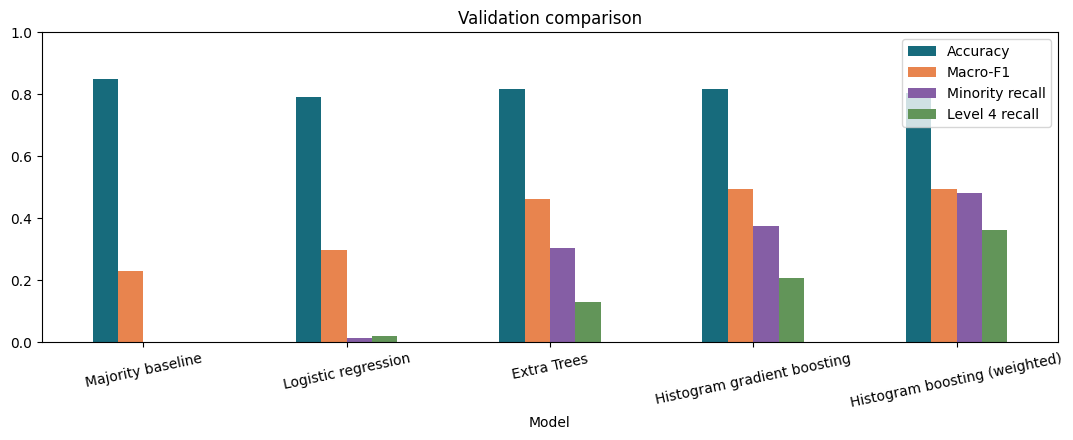

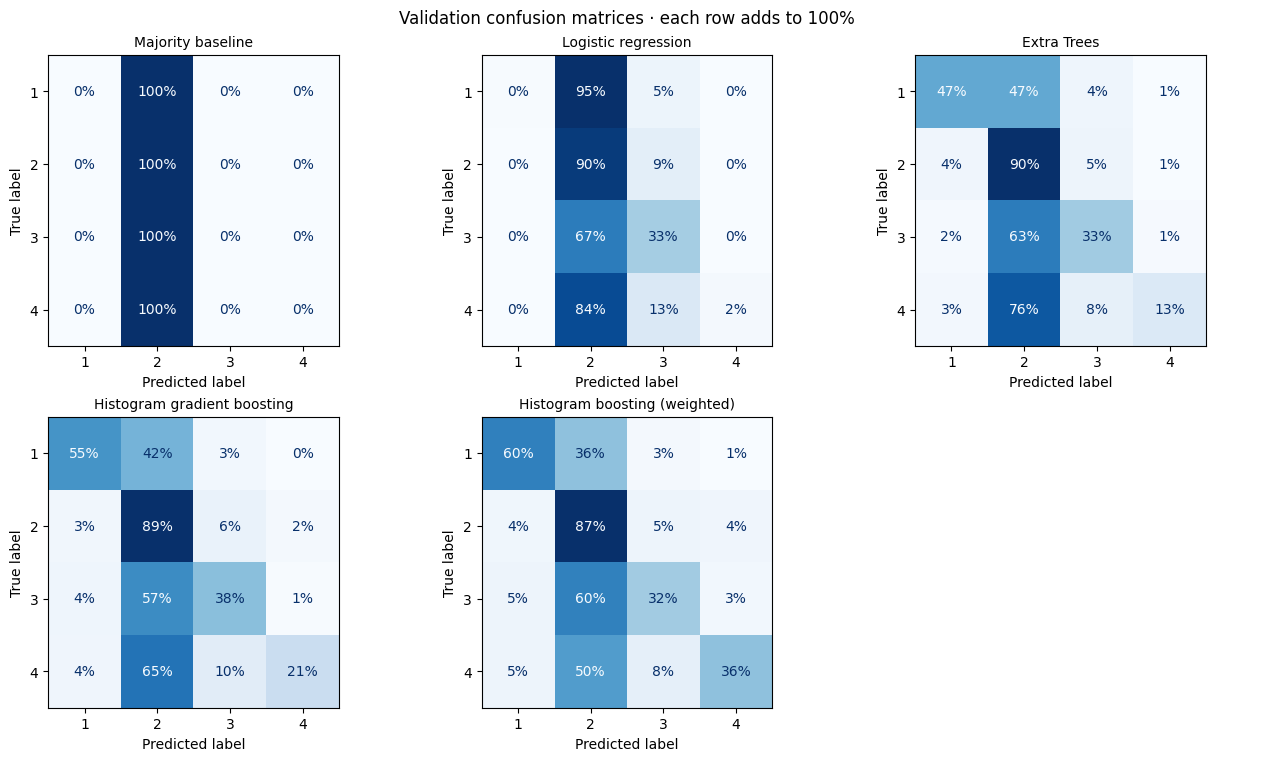

In [10]:
baseline_pred = baseline.predict(X_valid)
results = [{
    "Model": "Majority baseline", "Decision": "Default",
    **metric_row(y_valid, baseline_pred, (baseline_pred == 3).astype(float)),
}]
validation_predictions = {"Majority baseline": baseline_pred}
candidate_multipliers = {}

for name, model in models.items():
    print("Training", name, flush=True)
    started = perf_counter()
    # Limit CPU use on Kaggle and on machines with many cores.
    fit_settings = {}
    if name == weighted_boost_name:
        fit_settings["histgradientboostingclassifier__sample_weight"] = row_weights
    with threadpool_limits(limits=THREADS):
        model.fit(X_train, y_train, **fit_settings)
        valid_scores = model.predict_proba(X_valid)
    multipliers = tune_multipliers(valid_scores, y_valid)
    candidate_multipliers[name] = multipliers
    default_predictions = valid_scores.argmax(axis=1)
    tuned_predictions = predict_levels(valid_scores, multipliers)
    for decision, predictions in [("Default", default_predictions), ("Tuned", tuned_predictions)]:
        results.append({
            "Model": name, "Decision": decision,
            **metric_row(y_valid, predictions, valid_scores[:, 3]),
        })
    validation_predictions[name] = tuned_predictions
    print(f"Finished in {perf_counter() - started:.1f} seconds.", flush=True)

validation_results = pd.DataFrame(results).set_index(["Model", "Decision"])
display(validation_results.round(4))

best_name = validation_results.xs("Tuned", level="Decision")["Macro-F1"].idxmax()
best_model = models[best_name]
best_multipliers = candidate_multipliers[best_name]
print("Selected by validation macro-F1:", best_name)
display(pd.Series(best_multipliers, index=CLASS_NAMES, name="Score multiplier").to_frame())

selected_rows = validation_results.loc[
    validation_results.index.get_level_values("Decision") == "Tuned"
].droplevel("Decision")
chart_rows = pd.concat([validation_results.loc[[("Majority baseline", "Default")]]
                        .droplevel("Decision"), selected_rows])
chart_rows[["Accuracy", "Macro-F1", "Minority recall", "Level 4 recall"]].plot.bar(
    figsize=(11, 4.5), ylim=(0, 1), rot=12, title="Validation comparison",
    color=["#176b7c", "#e8844e", "#855ea5", "#629559"],
)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), layout="constrained")
axes = axes.ravel()
axes[-1].set_axis_off()
for ax, (name, predictions) in zip(axes, validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_valid + 1, predictions + 1, labels=[1, 2, 3, 4],
        normalize="true", values_format=".0%", cmap="Blues",
        colorbar=False, ax=ax,
    )
    ax.set_title(name, fontsize=10)
fig.suptitle("Validation confusion matrices · each row adds to 100%")
plt.show()

## 6. Evaluate the chosen model on the holdouts

The model and its score multipliers are now fixed. Each holdout keeps its sampled class mix. Compare the model with the majority baseline on the same records. The confusion matrices show raw counts and percentages within each actual severity level. The precision–recall curve shows how well the model ranks Level 4 records, with the achieved precision and recall marked for the final decision rule.

The dot can sit off the curve because the final four-class decision compares all four scores, while the curve varies a single cutoff on the Level 4 score.

In [11]:
test_results = []
test_reports = {}
best_test_scores = {}
test_predictions = {}
test_labels = {}

for name in ["Time test", "Location test"]:
    part = splits[name]
    X_test = make_features(part)
    actual = make_labels(part)
    with threadpool_limits(limits=THREADS):
        scores = best_model.predict_proba(X_test)
    predictions = predict_levels(scores, best_multipliers)
    reference = baseline.predict(X_test)
    test_results.append({
        "Holdout": name, "Model": "Majority baseline", "Rows": len(part),
        **metric_row(actual, reference, (reference == 3).astype(float)),
    })
    test_results.append({
        "Holdout": name, "Model": best_name, "Rows": len(part),
        **metric_row(actual, predictions, scores[:, 3]),
    })
    test_reports[name] = pd.DataFrame(classification_report(
        actual, predictions, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )).T.loc[CLASS_NAMES]
    test_labels[name] = actual
    best_test_scores[name] = scores
    test_predictions[name] = predictions
    print(f"{name}: {len(part):,} rows, {part['Start_Time'].min():%Y-%m-%d} to {part['Start_Time'].max():%Y-%m-%d}")

holdout_results = pd.DataFrame(test_results).set_index(["Holdout", "Model"])
display(holdout_results.round(4))
for name, report in test_reports.items():
    print(name, "· per-class scores")
    display(report.round(4))

y_test = test_labels["Time test"]
best_predictions = test_predictions["Time test"]
# Reuse the road labels for subgroup analysis on the primary time test.
test_data["Road_Type"] = road_type(test_data["Street"])

Time test: 79,125 rows, 2022-07-01 to 2022-09-30
Location test: 7,522 rows, 2022-07-01 to 2022-09-30


Rows  Accuracy  Macro-F1  \
Holdout       Model                                                      
Time test     Majority baseline              79125    0.8726    0.2330   
              Histogram boosting (weighted)  79125    0.8079    0.3536   
Location test Majority baseline               7522    0.8697    0.2326   
              Histogram boosting (weighted)   7522    0.8688    0.2324   

                                             Macro precision  \
Holdout       Model                                            
Time test     Majority baseline                       0.2182   
              Histogram boosting (weighted)           0.5781   
Location test Majority baseline                       0.2174   
              Histogram boosting (weighted)           0.2174   

                                             Balanced accuracy  \
Holdout       Model                                              
Time test     Majority baseline                         0.2500   
              Histogram boosting (weighted)             0.3952   
Location test Majority baseline                         0.2500   
              Histogram boosting (weighted)             0.2497   

                                             Minority recall  \
Holdout       Model                                            
Time test     Majority baseline                       0.0000   
              Histogram boosting (weighted)           0.1571   
Location test Majority baseline                       0.0000   
              Histogram boosting (weighted)           0.0000   

                                             Level 4 precision  \
Holdout       Model                                              
Time test     Majority baseline                         0.0000   
              Histogram boosting (weighted)             0.1696   
Location test Majority baseline                         0.0000   
              Histogram boosting (weighted)             0.0000   

                                             Level 4 recall  \
Holdout       Model                                           
Time test     Majority baseline                      0.0000   
              Histogram boosting (weighted)          0.3135   
Location test Majority baseline                      0.0000   
              Histogram boosting (weighted)          0.0000   

                                             Level 4 average precision  \
Holdout       Model                                                      
Time test     Majority baseline                                 0.0271   
              Histogram boosting (weighted)                     0.1256   
Location test Majority baseline                                 0.0646   
              Histogram boosting (weighted)                     0.0824   

                                             Levels 3–4 recall  
Holdout       Model                                             
Time test     Majority baseline                         0.0000  
              Histogram boosting (weighted)             0.3961  
Location test Majority baseline                         0.0000  
              Histogram boosting (weighted)             0.0000

Time test · per-class scores


,precision,recall,f1-score,support
Level 1,1.0000,0.0008,0.0015,3897.0
Level 2,0.8930,0.8942,0.8936,69048.0
Level 3,0.2498,0.3722,0.2990,4033.0
Level 4,0.1696,0.3135,0.2201,2147.0


Location test · per-class scores


,precision,recall,f1-score,support
Level 1,0.0000,0.0000,0.0000,178.0
Level 2,0.8696,0.9989,0.9298,6542.0
Level 3,0.0000,0.0000,0.0000,316.0
Level 4,0.0000,0.0000,0.0000,486.0


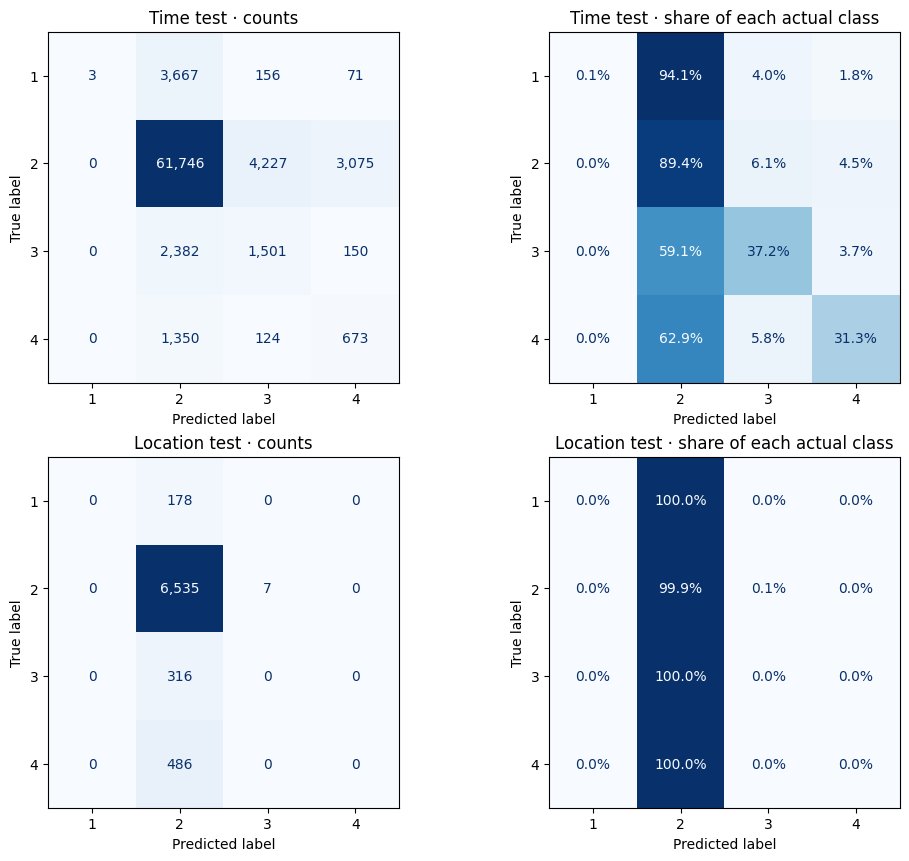

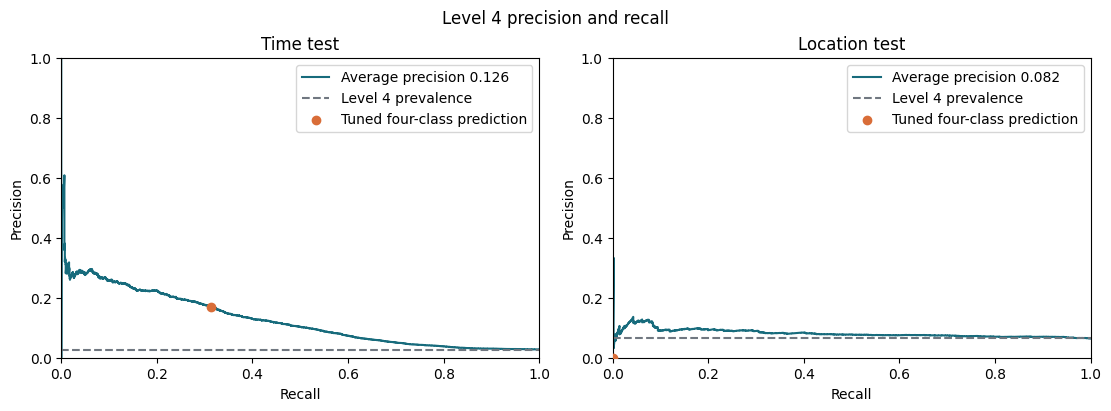

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), layout="constrained")
for index, name in enumerate(test_predictions):
    actual = test_labels[name] + 1
    predictions = test_predictions[name] + 1
    for ax, normalization, format_code, title in [
        (axes[index, 0], None, ",d", "counts"),
        (axes[index, 1], "true", ".1%", "share of each actual class"),
    ]:
        ConfusionMatrixDisplay.from_predictions(
            actual, predictions, labels=[1, 2, 3, 4],
            normalize=normalization, values_format=format_code, cmap="Blues",
            colorbar=False, ax=ax,
        )
        ax.set_title(f"{name} · {title}")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, name in zip(axes, best_test_scores):
    highest_impact = test_labels[name] == 3
    scores = best_test_scores[name][:, 3]
    precision, recall, _ = precision_recall_curve(highest_impact, scores)
    metrics = holdout_results.loc[(name, best_name)]
    ax.plot(recall, precision, color="#176b7c",
            label=f"Average precision {metrics['Level 4 average precision']:.3f}")
    ax.axhline(highest_impact.mean(), color="#707780", linestyle="--", label="Level 4 prevalence")
    ax.scatter(metrics["Level 4 recall"], metrics["Level 4 precision"],
               color="#d96d38", zorder=3, label="Tuned four-class prediction")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision", title=name)
    ax.legend(loc="upper right")
fig.suptitle("Level 4 precision and recall")
plt.show()

### Later reporting shift

The next table checks performance from October 2022 onward. Use its class counts and provider mix to interpret the scores. The final rule can still predict Levels 1 and 3, even if neither is observed in this period. Focus on Level 4 precision and recall and the count of predictions for unsupported labels. Four-class macro-F1 and minority recall are omitted for this shift check because some labels have no actual examples.

In [13]:
split_distribution = pd.DataFrame({
    name: severity_counts(part) for name, part in splits.items()
}).T
split_distribution.columns = CLASS_NAMES
print("Actual class shares (%)")
display((100 * split_distribution.div(split_distribution.sum(axis=1), axis=0)).round(2))
source_shares = pd.DataFrame({
    name: part["Source"].fillna("Unknown").value_counts(normalize=True) * 100
    for name, part in splits.items()
}).T.fillna(0)
print("Reporting provider shares (%), for diagnosis only")
display(source_shares.round(2))

shift_data = splits["Later reporting shift"]
X_shift = make_features(shift_data)
y_shift = make_labels(shift_data)
with threadpool_limits(limits=THREADS):
    shift_scores = best_model.predict_proba(X_shift)
shift_predictions = predict_levels(shift_scores, best_multipliers)
shift_rows = []
for name, predictions in [
    ("Majority baseline", baseline.predict(X_shift)), (best_name, shift_predictions),
]:
    level_4 = classification_report(
        y_shift, predictions, labels=[3], target_names=["Level 4"], output_dict=True, zero_division=0,
    )["Level 4"]
    shift_rows.append({
        "Model": name,
        "Rows": len(y_shift),
        "Accuracy": accuracy_score(y_shift, predictions),
        "Level 4 precision": level_4["precision"],
        "Level 4 recall": level_4["recall"],
        "Actual Level 4 records": int(level_4["support"]),
        "Predictions with no actual examples": np.count_nonzero(~np.isin(predictions, np.unique(y_shift))),
    })
shift_results = pd.DataFrame(shift_rows).set_index("Model")
display(shift_results.round(4))

Actual class shares (%)


,Level 1,Level 2,Level 3,Level 4
Train,1.05,86.23,10.78,1.93
Validation,6.21,84.96,6.67,2.15
Time test,4.93,87.26,5.10,2.71
Location test,2.37,86.97,4.20,6.46
Later reporting shift,0.00,97.69,0.00,2.31


Reporting provider shares (%), for diagnosis only


Source,Source1,Source2,Source3
Train,68.86,29.60,1.53
Validation,80.07,18.62,1.31
Time test,85.25,13.60,1.14
Location test,91.27,8.19,0.55
Later reporting shift,100.00,0.00,0.00


,Rows,Accuracy,Level 4 precision,Level 4 recall,Actual Level 4 records,Predictions with no actual examples
Model,,,,,,
Majority baseline,117953,0.9769,0.0000,0.0000,2726,0
Histogram boosting (weighted),117953,0.8497,0.1549,0.3111,2726,11535


## 7. Investigate severe crashes and model errors

Use the primary time test here, after choosing the model on validation data. **Severity 4** is the dataset's highest traffic-impact category. A group's severity 4 share is the percentage of its **recorded crashes** labeled severity 4. Estimating crash risk per trip would require traffic exposure data.

The tables require at least 100 records per group. The highlighted severity 4 shares and group-level recall also require at least 25 actual severity 4 records.

In [14]:
import numpy as np
import pandas as pd

MIN_GROUP_RECORDS = 100
MIN_SEVERITY_4_RECORDS = 25

# Use NumPy arrays to keep every prediction paired with its original test row.
weather_column = "Weather_Group" if "Weather_Group" in test_data else "Weather_Condition"
column_names = {"Start_Time": "Start_Time", "State": "State", weather_column: "Weather"}
if "Civil_Twilight" in test_data:
    column_names["Civil_Twilight"] = "Lighting"
if "Road_Type" in test_data:
    column_names["Road_Type"] = "Road type"
elif "Junction" in test_data:
    column_names["Junction"] = "Junction flag"

evaluation_rows = test_data[list(column_names)].rename(columns=column_names).copy()
evaluation_rows["Actual_Severity"] = np.asarray(y_test).reshape(-1) + 1
evaluation_rows["Predicted_Severity"] = np.asarray(best_predictions).reshape(-1) + 1

group_columns = [name for name in column_names.values() if name != "Start_Time"]
for column in group_columns:
    evaluation_rows[column] = evaluation_rows[column].astype("string").fillna("Unknown")
crash_time = pd.to_datetime(evaluation_rows["Start_Time"], errors="coerce")
evaluation_rows["Hour"] = crash_time.dt.strftime("%H:00").fillna("Unknown")
group_columns.insert(1, "Hour")

actual = evaluation_rows["Actual_Severity"]
predicted = evaluation_rows["Predicted_Severity"]
evaluation_rows["Severity_4"] = actual.eq(4)
evaluation_rows["Correct_Severity_4"] = actual.eq(4) & predicted.eq(4)
evaluation_rows["Missed_Severity_4"] = actual.eq(4) & predicted.lt(4)
evaluation_rows["Severity_4_Predicted_1_or_2"] = actual.eq(4) & predicted.le(2)
evaluation_rows["Wrong"] = actual.ne(predicted)
overall_severity_4_share = 100 * evaluation_rows["Severity_4"].mean()


def summarize_groups(group_column):
    # Count recorded crashes and summarize the model's errors for one group.
    summary = evaluation_rows.groupby(group_column).agg(
        Records=("Actual_Severity", "size"),
        Severity_4=("Severity_4", "sum"),
        Correct_Severity_4=("Correct_Severity_4", "sum"),
        Missed_Severity_4=("Missed_Severity_4", "sum"),
        Severity_4_Predicted_1_or_2=("Severity_4_Predicted_1_or_2", "sum"),
        Wrong=("Wrong", "sum"),
    )
    summary["Severity_4_share_%"] = 100 * summary["Severity_4"] / summary["Records"]
    summary["Wrong_%"] = 100 * summary["Wrong"] / summary["Records"]
    enough_severe_cases = summary["Severity_4"].where(
        summary["Severity_4"] >= MIN_SEVERITY_4_RECORDS
    )
    summary["Severity_4_recall_%"] = 100 * summary["Correct_Severity_4"] / enough_severe_cases
    return summary.loc[summary["Records"] >= MIN_GROUP_RECORDS]


group_summaries = {column: summarize_groups(column) for column in group_columns}

print(f"Overall severity 4 share on the primary time test was {overall_severity_4_share:.2f}%.")
pattern_columns = ["Records", "Severity_4", "Severity_4_share_%"]
for group_name, summary in group_summaries.items():
    known_groups = summary.drop(index="Unknown", errors="ignore")
    highest_shares = known_groups.sort_values("Severity_4_share_%", ascending=False)
    supported_shares = highest_shares.loc[highest_shares["Severity_4"] >= MIN_SEVERITY_4_RECORDS]
    if not supported_shares.empty:
        top = supported_shares.iloc[0]
        print(
            f"{group_name} | {top.name} had {top['Severity_4']:,.0f} severity 4 records "
            f"out of {top['Records']:,.0f} recorded crashes ({top['Severity_4_share_%']:.2f}%)."
        )
    print(f"{group_name} groups with the highest observed severity 4 share")
    display(highest_shares[pattern_columns].head(8).round(2))

Overall severity 4 share on the primary time test was 2.71%.
State | AR had 60 severity 4 records out of 476 recorded crashes (12.61%).
State groups with the highest observed severity 4 share


,Records,Severity_4,Severity_4_share_%
State,,,
AR,476,60,12.61
DE,176,21,11.93
IN,727,77,10.59
GA,1626,137,8.43
IA,207,17,8.21
WI,519,40,7.71
MI,1495,94,6.29
NC,3324,204,6.14


Hour | 00:00 had 77 severity 4 records out of 1,321 recorded crashes (5.83%).
Hour groups with the highest observed severity 4 share


,Records,Severity_4,Severity_4_share_%
Hour,,,
00:00,1321,77,5.83
03:00,880,47,5.34
01:00,938,46,4.90
04:00,1284,62,4.83
02:00,951,42,4.42
05:00,2128,85,3.99
22:00,1910,71,3.72
09:00,3160,116,3.67


Weather | Cloudy had 165 severity 4 records out of 5,805 recorded crashes (2.84%).
Weather groups with the highest observed severity 4 share


,Records,Severity_4,Severity_4_share_%
Weather,,,
Light Drizzle,105,12,11.43
Fog,404,21,5.20
Cloudy,5805,165,2.84
Fair,42460,1181,2.78
Light Rain,2268,60,2.65
Heavy Rain,307,8,2.61
Haze,320,7,2.19
Partly Cloudy,9693,211,2.18


Lighting | Night had 614 severity 4 records out of 15,023 recorded crashes (4.09%).
Lighting groups with the highest observed severity 4 share


,Records,Severity_4,Severity_4_share_%
Lighting,,,
Night,15023,614,4.09
Day,63352,1461,2.31


Road type | Highway/route had 315 severity 4 records out of 8,076 recorded crashes (3.90%).
Road type groups with the highest observed severity 4 share


,Records,Severity_4,Severity_4_share_%
Road type,,,
Highway/route,8076,315,3.90
Numbered route,7888,276,3.50
Road/drive/lane,15345,501,3.26
Street/avenue,15441,445,2.88
Interstate,20597,386,1.87
Other,11484,211,1.84


In [15]:
# Separate errors by actual and predicted severity to see what was confused.
error_pairs = (
    evaluation_rows.loc[evaluation_rows["Wrong"]]
    .groupby(["Actual_Severity", "Predicted_Severity"])
    .size()
    .rename("Records")
    .sort_values(ascending=False)
)
print("Most common incorrect predictions")
display(error_pairs.head(8).to_frame())

error_columns = [
    "Records", "Wrong_%", "Severity_4", "Missed_Severity_4",
    "Severity_4_Predicted_1_or_2", "Severity_4_recall_%",
]
for group_name, summary in group_summaries.items():
    missed_most = summary.sort_values("Missed_Severity_4", ascending=False).head(8)
    if not missed_most.empty:
        top = missed_most.iloc[0]
        print(
            f"{group_name} | {top.name} had the most missed severity 4 cases "
            f"({top['Missed_Severity_4']:,.0f} of {top['Severity_4']:,.0f})."
        )
    print(f"{group_name} groups with the most missed severity 4 crashes")
    display(missed_most[error_columns].round(2))

Most common incorrect predictions


,,Records
Actual_Severity,Predicted_Severity,
2,3,4227
1,2,3667
2,4,3075
3,2,2382
4,2,1350
1,3,156
3,4,150
4,3,124


State | CA had the most missed severity 4 cases (383 of 383).
State groups with the most missed severity 4 crashes


,Records,Wrong_%,Severity_4,Missed_Severity_4,Severity_4_Predicted_1_or_2,Severity_4_recall_%
State,,,,,,
CA,19199,9.00,383,383,380,0.00
TX,5150,36.29,110,109,74,0.91
PA,3965,31.93,228,107,101,53.07
FL,9956,8.94,91,89,88,2.20
NC,3324,36.10,204,73,72,64.22
MI,1495,27.42,94,71,69,24.47
MD,1840,17.66,112,69,69,38.39
GA,1626,60.58,137,62,41,54.74


Hour | 14:00 had the most missed severity 4 cases (112 of 131).
Hour groups with the most missed severity 4 crashes


,Records,Wrong_%,Severity_4,Missed_Severity_4,Severity_4_Predicted_1_or_2,Severity_4_recall_%
Hour,,,,,,
14:00,5638,13.28,131,112,103,14.50
08:00,4887,30.51,140,105,99,25.00
15:00,6407,13.34,129,97,91,24.81
10:00,3293,20.29,107,86,81,19.63
06:00,3915,27.02,108,83,77,23.15
11:00,3610,17.53,120,82,75,31.67
13:00,4429,14.56,116,81,73,30.17
07:00,5323,26.51,99,81,74,18.18


... (2 outputs left out)

Lighting | Day had the most missed severity 4 cases (1,088 of 1,461).
Lighting groups with the most missed severity 4 crashes


,Records,Wrong_%,Severity_4,Missed_Severity_4,Severity_4_Predicted_1_or_2,Severity_4_recall_%
Lighting,,,,,,
Day,63352,18.11,1461,1088,1001,25.53
Night,15023,22.89,614,368,334,40.07
Unknown,750,38.67,72,18,15,75.00


Road type | Street/avenue had the most missed severity 4 cases (364 of 445).
Road type groups with the most missed severity 4 crashes


,Records,Wrong_%,Severity_4,Missed_Severity_4,Severity_4_Predicted_1_or_2,Severity_4_recall_%
Road type,,,,,,
Street/avenue,15441,15.76,445,364,357,18.20
Interstate,20597,25.13,386,348,272,9.84
Road/drive/lane,15345,20.36,501,246,243,50.90
Numbered route,7888,17.36,276,179,162,35.14
Highway/route,8076,17.83,315,172,163,45.40
Other,11484,13.53,211,161,150,23.70
Unknown,290,36.55,13,4,3,NaN


Compare severity 4 shares with the overall test share. Large counts of missed crashes can reflect the size of a group, so read them alongside its recall. A missing recall value means the group had fewer than 25 severity 4 cases.

Use groups with many recorded severity 4 crashes and elevated shares to prioritize road-safety investigations. Check whether those patterns recur in another period and consider traffic volume and reporting coverage when interpreting them.

## 8. Severity patterns dashboard

The dashboard compares the eight weather categories and states with the most records in the primary time test and shows all hours that meet the minimum group size. Hover to see the number of crashes behind each bar. The dashed line is the overall severity 4 share for this test.

In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

weather_chart = group_summaries["Weather"].drop(index="Unknown", errors="ignore")
weather_chart = weather_chart.nlargest(8, "Records")
state_chart = group_summaries["State"].drop(index="Unknown", errors="ignore")
state_chart = state_chart.nlargest(8, "Records")
hour_chart = group_summaries["Hour"].drop(index="Unknown", errors="ignore").sort_index()

dashboard = make_subplots(
    rows=3, cols=1,
    subplot_titles=("Weather", "State", "Recorded start hour"),
    vertical_spacing=0.10,
)
panels = [(weather_chart, "#167A79"), (state_chart, "#4169A1"), (hour_chart, "#895281")]

for row_number, (chart_data, color) in enumerate(panels, start=1):
    dashboard.add_trace(
        go.Bar(
            x=chart_data.index,
            y=chart_data["Severity_4_share_%"],
            marker_color=color,
            customdata=chart_data[["Records", "Severity_4"]],
            hovertemplate=(
                "%{x}<br>Severity 4 share: %{y:.2f}%"
                "<br>All recorded crashes: %{customdata[0]:,}"
                "<br>Severity 4 crashes: %{customdata[1]:,}<extra></extra>"
            ),
        ),
        row=row_number, col=1,
    )
    dashboard.add_hline(
        y=overall_severity_4_share, line_dash="dash", line_color="#585858",
        row=row_number, col=1,
    )
    dashboard.update_xaxes(type="category", tickangle=-25, automargin=True, row=row_number, col=1)

dashboard.update_yaxes(title_text="Severity 4 share", ticksuffix="%", rangemode="tozero", matches="y")
dashboard.update_layout(
    title="Severity 4 share in the primary time test",
    template="plotly_white",
    showlegend=False,
    height=920,
    margin={"l": 75, "r": 35, "t": 85, "b": 65},
)
dashboard.show()

## 9. Save the trained model and example output

Use `predict_severity()` to classify rows that contain the listed input columns. The predicted level uses the tuned decision rule. The four `Model score` columns are the classifier's original estimates and can be useful for ranking. The estimates have not been calibrated to represent real-world probabilities.

The model file contains the fitted preprocessing and classifier, class labels, decision multipliers and raw input columns. Use it with the `make_features()` and `predict_severity()` functions from this notebook and the recorded library versions. The dashboard HTML opens on its own in a browser after downloading it from Kaggle.

In [17]:
def predict_severity(records, bundle):
    missing = sorted(set(bundle["raw_input_columns"]) - set(records.columns))
    if missing:
        raise ValueError(f"Missing input columns: {', '.join(missing)}")
    features = make_features(records)
    with threadpool_limits(limits=THREADS):
        scores = bundle["model"].predict_proba(features)
    chosen = predict_levels(scores, bundle["score_multipliers"])
    result = pd.DataFrame(
        scores, index=records.index, columns=[f"Model score {level}" for level in range(1, 5)],
    )
    result.insert(0, "Predicted severity", chosen + 1)
    return result


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
bundle = {
    "model": best_model,
    "model_name": best_name,
    "raw_input_columns": RAW_FEATURES,
    "class_labels": [1, 2, 3, 4],
    "score_multipliers": best_multipliers,
}

model_path = OUTPUT_DIR / "accident_severity_model.joblib"
joblib.dump(bundle, model_path, compress=3)
validation_results.to_csv(OUTPUT_DIR / "validation_metrics.csv")
holdout_results.to_csv(OUTPUT_DIR / "holdout_metrics.csv")
shift_results.to_csv(OUTPUT_DIR / "reporting_shift_metrics.csv")
dashboard.write_html(OUTPUT_DIR / "severity_dashboard.html", include_plotlyjs=True)

versions = {
    "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": __import__("sklearn").__version__, "joblib": joblib.__version__,
}
(OUTPUT_DIR / "model_details.json").write_text(json.dumps({
    "model": best_name, "input_columns": RAW_FEATURES, "output_levels": [1, 2, 3, 4],
    "score_multipliers": best_multipliers.tolist(), "package_versions": versions,
}, indent=2), encoding="utf-8")

# Confirm the saved file produces the same output as the fitted model.
example_input = test_data.loc[:, RAW_FEATURES].head(3)
example_output = predict_severity(example_input, joblib.load(model_path))
assert np.array_equal(example_output["Predicted severity"], best_predictions[:3] + 1)
print("Inputs:", ", ".join(RAW_FEATURES))
display(example_output.round(3))
print("Model, metrics and dashboard saved to", OUTPUT_DIR)

Inputs: Start_Time, Street, Start_Lat, Start_Lng, Temperature(F), Humidity(%), Pressure(in), Visibility(mi), Wind_Speed(mph), Precipitation(in), Amenity, Bump, Crossing, Give_Way, Junction, No_Exit, Railway, Roundabout, Station, Stop, Traffic_Calming, Traffic_Signal, State, Weather_Condition, Sunrise_Sunset, Civil_Twilight


,Predicted severity,Model score 1,Model score 2,Model score 3,Model score 4
0,2,0.000,0.775,0.152,0.073
1,3,0.000,0.162,0.803,0.035
2,2,0.001,0.753,0.161,0.086


Model, metrics and dashboard saved to /kaggle/working
